# Fine-tune the gender classifier on FairFace

Fine-tunes the existing **`gender_mobilenetv3_model.pth`** (MobileNetV3-Large, classes `female`, `male`) on the
[FairFace](https://github.com/joojs/fairface) dataset (86,744 real-world face photos, balanced across 7 ethnic groups and both genders, CC BY 4.0).

**Why:** the current model was trained on celebrity photos. On real-world faces it recognises men well (93%) but only 58% of women,
dropping to 39–48% for Black and Indian women.

**How it matches the app:** every training face is detected and cropped exactly like the backend does it
(YuNet face detector → eyes rotated level → small margin), so the model learns from the same crops it will see in production.

### Before running (Kaggle)
1. **Settings → Accelerator → GPU T4 x2** and **Settings → Internet → On**.
2. **Add Input → Upload** a dataset containing `gender_mobilenetv3_model.pth`.
3. *(Optional)* **Add Input →** search `cashutosh/gender-classification-dataset` to check the model still works on the original 58k data.
4. **Run All** (about 45–60 minutes on a T4).

### Output (in `/kaggle/working`, download from the Output panel)
- `gender_mobilenetv3_fairface.pth` – the fine-tuned weights (same architecture, drop-in for the backend)
- `gender_mobilenetv3_fairface.json` – decision threshold, crop settings and evaluation results

In [1]:
# ---- Configuration ----
import os
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()
INPUT_DIR = Path("/kaggle/input") if ON_KAGGLE else Path.cwd()   # where uploaded inputs are searched
OUTPUT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path.cwd() / "output"
DATA_DIR = Path("/tmp/gender-training")                             # downloads stay out of the notebook output

BASE_MODEL_NAME = "gender_mobilenetv3_model.pth"
OUTPUT_NAME = "gender_mobilenetv3_fairface"

FAIRFACE_URL = "https://huggingface.co/datasets/HuggingFaceM4/FairFace/resolve/refs%2Fconvert%2Fparquet/0.25"
FAIRFACE_TRAIN_FILES = ["train/0000.parquet", "train/0001.parquet"]
FAIRFACE_VAL_FILES = ["validation/0000.parquet"]
YUNET_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"

# Face crop – must stay identical to Gendercount_backend/app/config.py
FACE_MARGIN_X, FACE_MARGIN_TOP, FACE_MARGIN_BOTTOM = 0.10, 0.10, 0.05
IMAGE_SIZE = 224
MIN_AGE_GROUP = 1          # FairFace age groups: 0 = "0-2" (infants are excluded), 1 = "3-9", 2 = "10-19", ...

# Training
EPOCHS = 6
BATCH_SIZE = 128
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
HOLDOUT_FRACTION = 0.05    # part of FairFace train used to pick the best epoch and the decision threshold
NUM_WORKERS = 4
MAX_TRAIN_IMAGES = None    # e.g. 3000 for a quick trial run
SEED = 42

CLASSES = ("female", "male")
RACES = ("East Asian", "Indian", "Black", "White", "Middle Eastern", "Latino_Hispanic", "Southeast Asian")

## 1. Setup and downloads

In [3]:
import io
import json
import random
import threading
import time
import urllib.request
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import mobilenet_v3_large

assert tuple(map(int, cv2.__version__.split(".")[:2])) >= (4, 8), "OpenCV 4.8+ is required for the YuNet face detector"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else " – training on CPU will be very slow"))

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def download(url: str, target: Path) -> Path:
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        print(f"Downloading {target.name} ...")
        urllib.request.urlretrieve(url, target)
    return target


yunet_path = download(YUNET_URL, DATA_DIR / "face_detection_yunet_2023mar.onnx")
train_files = [download(f"{FAIRFACE_URL}/{name}", DATA_DIR / "fairface" / name) for name in FAIRFACE_TRAIN_FILES]
val_files = [download(f"{FAIRFACE_URL}/{name}", DATA_DIR / "fairface" / name) for name in FAIRFACE_VAL_FILES]

base_model_path = next(INPUT_DIR.rglob(BASE_MODEL_NAME), None)
assert base_model_path, f"{BASE_MODEL_NAME} not found under {INPUT_DIR} – add it as a notebook input"
print(f"Base model: {base_model_path}")

Device: cuda (Tesla T4)
Base model: /kaggle/input/datasets/sudhan44/mobilenetv3-model/gender_mobilenetv3_model.pth


## 2. Face crops – same as the backend

Each FairFace photo goes through the backend's face detector. The largest face is rotated so the eyes are level and cropped
with the backend's margins. Crops are kept in memory as JPEG bytes.

In [4]:
_detectors = threading.local()


def detect_faces(image: np.ndarray) -> np.ndarray:
    # YuNet rows: x, y, w, h, right eye (x, y), left eye (x, y), nose, mouth corners, score. One detector per thread.
    if not hasattr(_detectors, "model"):
        _detectors.model = cv2.FaceDetectorYN.create(str(yunet_path), "", (320, 320), 0.5, 0.3, 5000)
    _detectors.model.setInputSize((image.shape[1], image.shape[0]))
    _, faces = _detectors.model.detect(image)
    return np.empty((0, 15), np.float32) if faces is None else faces


def align_face(image: np.ndarray, face: np.ndarray) -> np.ndarray:
    # Crop the face with the backend margins, rotated so the eyes are level.
    x, y, w, h = face[:4]
    (right_x, right_y), (left_x, left_y) = face[4:6], face[6:8]
    angle = np.degrees(np.arctan2(left_y - right_y, left_x - right_x))
    center = (x + w / 2, y + h / 2)
    left = x - FACE_MARGIN_X * w
    top = y - FACE_MARGIN_TOP * h
    size = (round(w * (1 + 2 * FACE_MARGIN_X)), round(h * (1 + FACE_MARGIN_TOP + FACE_MARGIN_BOTTOM)))
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    matrix[:, 2] -= (left, top)
    return cv2.warpAffine(image, matrix, size, flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)


def largest_face_crop(image: np.ndarray):
    faces = detect_faces(image)
    if len(faces) == 0:
        return None
    return align_face(image, max(faces, key=lambda face: face[2] * face[3]))


def crop_row(row: dict):
    image = cv2.imdecode(np.frombuffer(row["image"]["bytes"], np.uint8), cv2.IMREAD_COLOR)
    crop = None if image is None else largest_face_crop(image)
    if crop is None:
        return None
    _, jpeg = cv2.imencode(".jpg", crop, [cv2.IMWRITE_JPEG_QUALITY, 95])
    # FairFace gender: 0 = Male, 1 = Female  ->  model classes: 0 = female, 1 = male
    return jpeg.tobytes(), 1 - row["gender"], row["race"]


def build_crops(files, limit=None):
    rows = []
    for file in files:
        for batch in pq.ParquetFile(file).iter_batches(batch_size=2048, columns=["image", "gender", "race", "age"]):
            rows += [row for row in batch.to_pylist() if row["age"] >= MIN_AGE_GROUP]
    if limit:
        rows = random.sample(rows, min(limit, len(rows)))
    start = time.time()
    with ThreadPoolExecutor(os.cpu_count()) as pool:
        results = list(pool.map(crop_row, rows))
    kept = [result for result in results if result is not None]
    print(f"{len(kept):,} face crops from {len(rows):,} photos ({len(rows) - len(kept)} without a detectable face) in {time.time() - start:.0f}s")
    crops, labels, races = zip(*kept)
    return list(crops), np.array(labels), np.array(races)


train_crops, train_labels, train_races = build_crops(train_files, MAX_TRAIN_IMAGES)
val_crops, val_labels, val_races = build_crops(val_files)

84,874 face crops from 84,952 photos (78 without a detectable face) in 246s
10,746 face crops from 10,755 photos (9 without a detectable face) in 32s


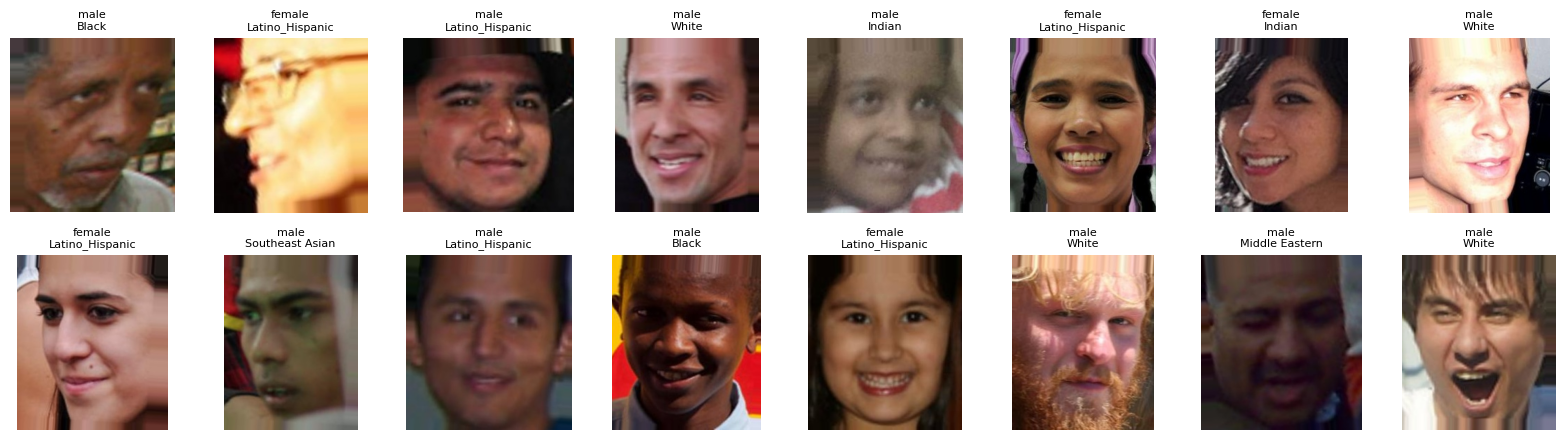

In [5]:
# Preview: these are exactly the kind of crops the backend sends to the classifier
def decode_rgb(jpeg: bytes) -> np.ndarray:
    return cv2.cvtColor(cv2.imdecode(np.frombuffer(jpeg, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for axis, index in zip(axes.flat, random.sample(range(len(train_crops)), 16)):
    axis.imshow(decode_rgb(train_crops[index]))
    axis.set_title(f"{CLASSES[train_labels[index]]}\n{RACES[train_races[index]]}", fontsize=8)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 3. Datasets and augmentation

Training images are randomly degraded the way faces look in group photos: very small (14–56 px wide), blurred,
JPEG-compressed, slightly rotated or shifted, with different lighting. Sampling is balanced over ethnicity × gender.
Validation uses exactly the backend's preprocessing.

In [6]:
class Degrade:
    # Randomly simulate small, blurry or heavily compressed faces from group photos.
    def __call__(self, image: np.ndarray) -> np.ndarray:
        height, width = image.shape[:2]
        if random.random() < 0.35:
            small_width = random.randint(14, 56)
            small = cv2.resize(image, (small_width, max(1, round(height * small_width / width))), interpolation=cv2.INTER_AREA)
            image = cv2.resize(small, (width, height), interpolation=cv2.INTER_LINEAR)
        if random.random() < 0.15:
            image = cv2.GaussianBlur(image, (0, 0), random.uniform(0.5, 1.5))
        if random.random() < 0.3:
            _, jpeg = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, random.randint(30, 90)])
            image = cv2.imdecode(jpeg, cv2.IMREAD_UNCHANGED)
        return image


normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_transform = transforms.Compose([
    Degrade(),
    transforms.ToPILImage(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.25, hue=0.03),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    normalize,
])

# Identical to the backend: PIL image -> Resize((224, 224)) -> ToTensor -> Normalize
eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    normalize,
])


class FaceCrops(Dataset):
    def __init__(self, crops, labels, transform):
        self.crops, self.labels, self.transform = crops, labels, transform

    def __len__(self):
        return len(self.crops)

    def __getitem__(self, index):
        return self.transform(decode_rgb(self.crops[index])), int(self.labels[index])


# Hold out a stratified slice of FairFace train for choosing the best epoch and the decision threshold.
# The official FairFace validation set is only used for the final, unbiased report.
groups = train_races * 2 + train_labels
holdout_mask = np.zeros(len(groups), bool)
for group in np.unique(groups):
    members = np.flatnonzero(groups == group)
    holdout_mask[np.random.choice(members, max(1, round(len(members) * HOLDOUT_FRACTION)), replace=False)] = True

fit_index, holdout_index = np.flatnonzero(~holdout_mask), np.flatnonzero(holdout_mask)
fit_set = FaceCrops([train_crops[i] for i in fit_index], train_labels[fit_index], train_transform)
holdout_set = FaceCrops([train_crops[i] for i in holdout_index], train_labels[holdout_index], eval_transform)
val_set = FaceCrops(val_crops, val_labels, eval_transform)

group_counts = Counter(groups[fit_index])
sample_weights = [1.0 / group_counts[group] for group in groups[fit_index]]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(fit_index), replacement=True)

loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda", persistent_workers=NUM_WORKERS > 0)
fit_loader = DataLoader(fit_set, sampler=sampler, drop_last=True, **loader_options)
holdout_loader = DataLoader(holdout_set, **loader_options)
val_loader = DataLoader(val_set, **loader_options)
print(f"fit: {len(fit_set):,}  holdout: {len(holdout_set):,}  FairFace validation: {len(val_set):,}")

fit: 80,630  holdout: 4,244  FairFace validation: 10,746


## 4. Load the current model and measure the baseline

Evaluation matches the backend: each face is classified together with its mirror image and the probabilities are averaged.

In [7]:
def load_model(weights_path: Path) -> nn.Module:
    model = mobilenet_v3_large(weights=None)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(CLASSES))
    model.load_state_dict(torch.load(weights_path, map_location="cpu", weights_only=True))
    return model.to(device)


@torch.inference_mode()
def female_probabilities(model: nn.Module, loader: DataLoader) -> np.ndarray:
    model.eval()
    probabilities = []
    for images, _ in loader:
        images = images.to(device, non_blocking=True)
        averaged = (model(images).softmax(1) + model(images.flip(3)).softmax(1)) / 2
        probabilities.append(averaged[:, 0].float().cpu())
    return torch.cat(probabilities).numpy()


def predict(p_female: np.ndarray, threshold: float) -> np.ndarray:
    return np.where(p_female >= threshold, 0, 1)  # 0 = female, 1 = male


def recalls(predictions: np.ndarray, labels: np.ndarray):
    women, men = labels == 0, labels == 1
    return (predictions[women] == 0).mean(), (predictions[men] == 1).mean()


def best_threshold(p_female: np.ndarray, labels: np.ndarray):
    # Threshold on P(female) that maximises balanced accuracy (equal weight to women and men).
    scores = {round(t, 2): np.mean(recalls(predict(p_female, t), labels)) for t in np.arange(0.2, 0.81, 0.01)}
    threshold = max(scores, key=scores.get)
    return threshold, scores[threshold]


def report(title: str, p_female: np.ndarray, labels: np.ndarray, races: np.ndarray, threshold: float) -> dict:
    predictions = predict(p_female, threshold)
    print(f"\n{title}  (female if P(female) >= {threshold:.2f})")
    print(f"{'group':18s}{'accuracy':>10s}{'men':>9s}{'women':>9s}{'faces':>8s}")
    results = {}
    for name, mask in [(race, races == index) for index, race in enumerate(RACES)] + [("ALL", np.ones_like(labels, bool))]:
        women, men = recalls(predictions[mask], labels[mask])
        accuracy = (predictions[mask] == labels[mask]).mean()
        results[name] = {"accuracy": round(float(accuracy), 4), "men": round(float(men), 4), "women": round(float(women), 4)}
        print(f"{name:18s}{accuracy:10.1%}{men:9.1%}{women:9.1%}{mask.sum():8d}")
    return results


base_model = load_model(base_model_path)
baseline_val = female_probabilities(base_model, val_loader)
baseline_results = report("BEFORE fine-tuning – FairFace validation", baseline_val, val_labels, val_races, 0.5)


BEFORE fine-tuning – FairFace validation  (female if P(female) >= 0.50)
group               accuracy      men    women   faces
East Asian             72.1%    89.5%    54.9%    1498
Indian                 67.3%    91.7%    43.4%    1497
Black                  63.9%    94.0%    32.6%    1530
White                  74.1%    92.7%    52.7%    2037
Middle Eastern         80.6%    94.0%    53.0%    1199
Latino_Hispanic        72.3%    91.1%    54.4%    1604
Southeast Asian        69.5%    89.4%    48.1%    1381
ALL                    71.3%    91.9%    48.4%   10746


## 5. Fine-tune

All layers are trained, starting from the current weights, with a low learning rate (warm-up, then cosine decay),
mixed precision on GPU and label smoothing. After each epoch the hold-out slice picks the best epoch and decision threshold.

In [8]:
model = load_model(base_model_path)
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LEARNING_RATE, total_steps=EPOCHS * len(fit_loader), pct_start=0.15)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(enabled=use_amp)

best = {"score": -1.0}
for epoch in range(1, EPOCHS + 1):
    model.train()
    start, total_loss, correct, seen = time.time(), 0.0, 0, 0
    for images, labels in fit_loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device.type, enabled=use_amp):
            logits = model(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        seen += len(labels)

    threshold, score = best_threshold(female_probabilities(model, holdout_loader), holdout_set.labels)
    women, men = recalls(predict(female_probabilities(model, val_loader), threshold), val_labels)
    print(f"epoch {epoch}/{EPOCHS}  loss {total_loss / seen:.4f}  train acc {correct / seen:.1%}  "
          f"hold-out balanced acc {score:.1%} (threshold {threshold:.2f})  validation women {women:.1%} men {men:.1%}  "
          f"[{time.time() - start:.0f}s]")
    if score > best["score"]:
        best = {"score": score, "epoch": epoch, "threshold": threshold,
                "state": {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}}

print(f"\nBest epoch: {best['epoch']} (hold-out balanced accuracy {best['score']:.1%}, threshold {best['threshold']:.2f})")
model.load_state_dict(best["state"])

epoch 1/6  loss 0.5630  train acc 77.1%  hold-out balanced acc 85.1% (threshold 0.49)  validation women 83.3% men 87.7%  [275s]
epoch 2/6  loss 0.4193  train acc 85.8%  hold-out balanced acc 88.6% (threshold 0.53)  validation women 86.2% men 90.3%  [265s]
epoch 3/6  loss 0.3820  train acc 88.2%  hold-out balanced acc 90.1% (threshold 0.53)  validation women 89.8% men 89.8%  [265s]
epoch 4/6  loss 0.3619  train acc 89.6%  hold-out balanced acc 91.0% (threshold 0.44)  validation women 91.7% men 90.2%  [265s]
epoch 5/6  loss 0.3496  train acc 90.4%  hold-out balanced acc 91.3% (threshold 0.46)  validation women 91.6% men 91.0%  [265s]
epoch 6/6  loss 0.3456  train acc 90.7%  hold-out balanced acc 91.4% (threshold 0.48)  validation women 91.1% men 91.5%  [265s]

Best epoch: 6 (hold-out balanced accuracy 91.4%, threshold 0.48)


<All keys matched successfully>

## 6. Results

In [9]:
final_val = female_probabilities(model, val_loader)
final_results = report("AFTER fine-tuning – FairFace validation", final_val, val_labels, val_races, best["threshold"])

print("\nChange (percentage points):")
for name in list(RACES) + ["ALL"]:
    before, after = baseline_results[name], final_results[name]
    print(f"{name:18s} accuracy {100 * (after['accuracy'] - before['accuracy']):+6.1f}   "
          f"men {100 * (after['men'] - before['men']):+6.1f}   women {100 * (after['women'] - before['women']):+6.1f}")


AFTER fine-tuning – FairFace validation  (female if P(female) >= 0.48)
group               accuracy      men    women   faces
East Asian             92.7%    91.7%    93.8%    1498
Indian                 91.2%    91.5%    91.0%    1497
Black                  84.8%    87.7%    81.8%    1530
White                  91.9%    92.0%    91.8%    2037
Middle Eastern         94.2%    94.0%    94.7%    1199
Latino_Hispanic        92.8%    91.6%    93.9%    1604
Southeast Asian        92.1%    91.8%    92.5%    1381
ALL                    91.3%    91.5%    91.1%   10746

Change (percentage points):
East Asian         accuracy  +20.6   men   +2.1   women  +38.9
Indian             accuracy  +23.9   men   -0.1   women  +47.6
Black              accuracy  +20.9   men   -6.3   women  +49.1
White              accuracy  +17.8   men   -0.6   women  +39.0
Middle Eastern     accuracy  +13.7   men   +0.0   women  +41.6
Latino_Hispanic    accuracy  +20.5   men   +0.5   women  +39.5
Southeast Asian    accurac

In [11]:
# Regression check on the original 58k dataset (only if `cashutosh/gender-classification-dataset` was added as an input)
original_results = None
original_dir = next((path for path in INPUT_DIR.rglob("Validation") if (path / "female").is_dir() and (path / "male").is_dir()), None)

if original_dir is None:
    print("Original 58k dataset not added as an input – skipping this check.")
else:
    files = []
    for label, name in enumerate(CLASSES):
        class_files = sorted((original_dir / name).iterdir())
        files += [(path, label) for path in random.sample(class_files, min(1500, len(class_files)))]

    def original_crop(item):
        image = cv2.imread(str(item[0]))
        crop = largest_face_crop(image)
        return cv2.imencode(".jpg", image if crop is None else crop)[1].tobytes(), item[1]

    with ThreadPoolExecutor(os.cpu_count()) as pool:
        crops, labels = zip(*pool.map(original_crop, files))
    original_loader = DataLoader(FaceCrops(list(crops), np.array(labels), eval_transform), **loader_options)
    labels = np.array(labels)
    before = (predict(female_probabilities(base_model, original_loader), 0.5) == labels).mean()
    after = (predict(female_probabilities(model, original_loader), best["threshold"]) == labels).mean()
    original_results = {"before": round(float(before), 4), "after": round(float(after), 4), "images": len(labels)}
    print(f"Original 58k validation ({len(labels):,} images): before {before:.1%}  after {after:.1%}")

Original 58k dataset not added as an input – skipping this check.


## 7. Save

Download both files from the **Output** panel (or `/kaggle/working`) and copy them to `Gendercount_backend/models/`.

In [12]:
weights_path = OUTPUT_DIR / f"{OUTPUT_NAME}.pth"
torch.save(best["state"], weights_path)

metadata = {
    "base_model": BASE_MODEL_NAME,
    "architecture": "mobilenet_v3_large, classifier[3] -> 2 classes",
    "classes": list(CLASSES),
    "female_threshold": best["threshold"],
    "best_epoch": best["epoch"],
    "face_crop": {"detector": "YuNet 2023mar", "align": "eyes level",
                  "margin_x": FACE_MARGIN_X, "margin_top": FACE_MARGIN_TOP, "margin_bottom": FACE_MARGIN_BOTTOM,
                  "input_size": IMAGE_SIZE},
    "fairface_validation": {"before": baseline_results, "after": final_results},
    "original_58k_validation": original_results,
}
(OUTPUT_DIR / f"{OUTPUT_NAME}.json").write_text(json.dumps(metadata, indent=2))
print(f"Saved {weights_path} ({weights_path.stat().st_size / 1e6:.1f} MB) and {OUTPUT_NAME}.json")

Saved /kaggle/working/gender_mobilenetv3_fairface.pth (17.0 MB) and gender_mobilenetv3_fairface.json


In [13]:
from IPython.display import FileLink
FileLink("gender_mobilenetv3_fairface.pth")


/kaggle/working/gender_mobilenetv3_fairface.pth

## 8. Export to ONNX for the backend

The backend runs the model with OpenCV, so it does not need PyTorch. This converts the fine-tuned model to ONNX
(same weights, different file format) and checks that OpenCV gives the same results as PyTorch.
Download the `.onnx` and `.json` files and copy them to `Gendercount_backend/models/`.

In [ ]:
import importlib.util
import subprocess
import sys

from IPython.display import FileLink, display

if importlib.util.find_spec("onnx") is None:  # needed by the exporter
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx"], check=True)

onnx_path = OUTPUT_DIR / f"{OUTPUT_NAME}.onnx"
export_model = model.cpu().eval()
torch.onnx.export(
    export_model, torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE), onnx_path,
    input_names=["input"], output_names=["logits"],
    dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, dynamo=False,
)

# Check on real validation faces: OpenCV (as used by the backend) must match PyTorch
images, _ = next(iter(DataLoader(val_set, batch_size=64)))
with torch.inference_mode():
    expected = export_model(images).softmax(1).numpy()
net = cv2.dnn.readNetFromONNX(str(onnx_path))
net.setInput(images.numpy())
logits = net.forward()
actual = np.exp(logits) / np.exp(logits).sum(axis=1, keepdims=True)
difference = np.abs(actual - expected).max()
assert difference < 1e-3, f"ONNX output differs from PyTorch by {difference}"
print(f"Saved {onnx_path} ({onnx_path.stat().st_size / 1e6:.1f} MB) - matches PyTorch (max difference {difference:.1e})")

display(FileLink(onnx_path.name), FileLink(f"{OUTPUT_NAME}.json"))